# Notebook 1 - PCA Report
Insurance Customer Segmentation (Unit 4). Dataset: public *Medical Cost / insurance* data (1,338 customers; age, sex, bmi, children, smoker, region, charges).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
try: df = pd.read_csv("insurance.csv")
except FileNotFoundError: df = pd.read_csv(url)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Data quality check

In [2]:
print(df.shape, 'missing:', df.isna().sum().sum(), 'duplicates:', df.duplicated().sum())
df.describe().round(1)

(1338, 7) missing: 0 duplicates: 1


,age,bmi,children,charges
count,1338.0,1338.0,1338.0,1338.0
mean,39.2,30.7,1.1,13270.4
std,14.0,6.1,1.2,12110.0
min,18.0,16.0,0.0,1121.9
25%,27.0,26.3,0.0,4740.3
50%,39.0,30.4,1.0,9382.0
75%,51.0,34.7,2.0,16639.9
max,64.0,53.1,5.0,63770.4


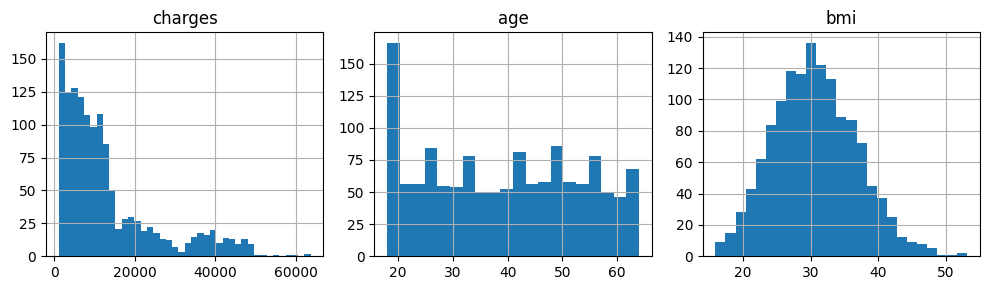

In [3]:
# one duplicate row exists; kept (plausible identical customers) so all files use n=1,338
fig,a=plt.subplots(1,3,figsize=(10,3)); df.charges.hist(bins=40,ax=a[0]); df.age.hist(bins=20,ax=a[1]); df.bmi.hist(bins=25,ax=a[2]); a[0].set_title('charges');a[1].set_title('age');a[2].set_title('bmi'); plt.tight_layout()

## 2. Scaling (mandatory)
PCA is variance-based, so unscaled features like `age` or `bmi` would dominate binary flags. We encode categoricals and apply `StandardScaler`.

In [4]:
# Clustering features: customer attributes only. 'charges' (cost) is the OUTCOME we analyse afterwards;
# 'region' is kept for profiling only (including it made clusters mere geographic splits).
X = pd.get_dummies(df.drop(columns=["charges","region"]), columns=["sex","smoker"], drop_first=True).astype(float)
Xs = StandardScaler().fit_transform(X)   # mandatory before PCA / K-Means
print(X.columns.tolist()); print(Xs.mean(0).round(2), Xs.std(0).round(2))

['age', 'bmi', 'children', 'sex_male', 'smoker_yes']
[-0. -0. -0. -0.  0.] [1. 1. 1. 1. 1.]


## 3. PCA and scree plot

[0.225 0.218 0.198 0.185 0.173] [0.225 0.443 0.641 0.827 1.   ]


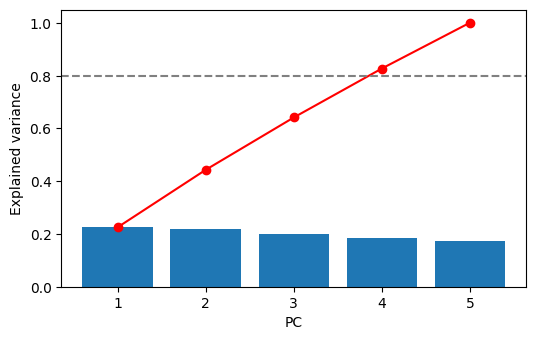

In [5]:
pca=PCA().fit(Xs); ev=pca.explained_variance_ratio_; cum=ev.cumsum()
print(ev.round(3), cum.round(3))
fig,ax=plt.subplots(figsize=(6,3.6)); ax.bar(range(1,len(ev)+1),ev); ax.plot(range(1,len(ev)+1),cum,'o-',c='r'); ax.axhline(.8,ls='--',c='grey'); ax.set_xlabel('PC'); ax.set_ylabel('Explained variance'); plt.show()

## 4. Choosing the number of components
Rule from the guide: retain 80-90% cumulative variance.

In [6]:
n=int(np.argmax(cum>=0.80)+1); print('Components kept:',n,'-> cumulative variance',round(cum[n-1],3))

Components kept: 4 -> cumulative variance 0.827


**Justification:** 4 components retain ~83% of variance, meeting the 80-90% target. Because the dataset has only 5 features, PCA here is mainly used for decorrelation and for the 2-D visual (PC1+PC2 = ~44% of variance, so the 2-D plot is an *approximate* view only).

## 5. Component interpretation

In [7]:
pd.DataFrame(pca.components_[:2].T,index=X.columns,columns=['PC1','PC2']).round(2)

,PC1,PC2
age,0.64,-0.30
bmi,0.67,0.02
children,0.31,0.05
sex_male,0.20,0.68
smoker_yes,0.03,0.67


PC1 is driven by **bmi, age, children** (body/life-stage dimension); PC2 by **sex_male and smoker_yes** (behavioural dimension).